<div align="center">

<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h3><strong>Program Implementasi Recipe</strong></h3>

<br>

<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:480px;">
  <li style="display:flex; justify-content:space-between;"><span>M. PADIL MANGULELE</span><span>(H061241071)</span></li>
</ul>

<br><br>
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>
<p><strong>2026</strong></p>

</div>

## **Implementasi Resep Komputasi Geofisika — Notebook 5**
**Daftar Resep yang Dipilih dari Buku AI Cookbook / Codex:**
1. **Resep 9 (R-MOD-001)**: Simulasi Difusi Panas Satu Dimensi (Hal. 134–136)
2. **Resep 10 (R-GEM-012)**: Layered Geothermal Gradient dan Heat-Flux Diagnostic (Hal. 140–142)

**Petunjuk Penggunaan:**
Notebook ini dibuat secara *self-contained* (mandiri). Seluruh perhitungan numerik, uji verifikasi, dan visualisasinya siap jalan (**Run All**) di Jupyter Notebook atau Google Colab. Dependensi hanya `numpy`, `scipy`, `pandas`, dan `matplotlib`. Semua data bersifat **sintetis** (tidak ada data lapangan), sesuai batas klaim yang ditetapkan buku.

**Alur kerja buku yang diikuti (Problem → Minimal Theory → Prompt → Code → Result → Optional Check):**
setiap resep di bawah disusun dengan urutan yang sama, dan ditutup dengan *check* (verifikasi) agar hasil dapat diperiksa, bukan sekadar "terlihat benar".

## **BAGIAN 1: RESEP 9 (R-MOD-001)**
### **Case Study: Simulasi Difusi Panas Satu Dimensi — Pemanasan Permukaan Tanah**

#### **1. Problem**
Menghitung perambatan gangguan termal (*thermal disturbance*) pada medium homogen satu dimensi. Studi kasus: permukaan tanah yang tiba-tiba terpanaskan (misalnya akibat aliran fluida panas atau permukaan yang terbakar) pada suhu tetap, sementara tanah di bawahnya awalnya bersuhu seragam.

#### **2. Minimal Theory (E-HEAT-001)**
Persamaan panas (difusi) satu dimensi:
$$\frac{\partial T}{\partial t} = \kappa \frac{\partial^2 T}{\partial z^2}$$
dengan $T$ suhu ($^\circ C$), $z$ kedalaman (m, **positif ke bawah**), $t$ waktu (s), dan $\kappa$ difusivitas termal ($m^2\,s^{-1}$).

Skema *explicit finite difference* (FTCS):
$$T_i^{n+1} = T_i^n + r\left(T_{i+1}^n - 2T_i^n + T_{i-1}^n\right), \qquad r = \frac{\kappa\,\Delta t}{\Delta z^2}$$
Skema hanya stabil bila **$r \le 1/2$**.

Sebagai pembanding (*verification*) dipakai solusi analitik medium semi-tak-hingga dengan suhu permukaan konstan $T_s$ dan suhu awal $T_0$:
$$T(z,t) = T_0 + (T_s - T_0)\,\operatorname{erfc}\!\left(\frac{z}{2\sqrt{\kappa t}}\right)$$
dengan panjang difusi $L_d = \sqrt{\kappa t}$.

**Catatan kontrak solver dari buku:**
- Spasi grid yang dipakai adalah **spasi aktual** (setelah pembulatan jumlah node), bukan `dz` yang diminta.
- Langkah waktu diperkecil bila perlu agar **waktu akhir tepat sama** dengan durasi yang diminta.
- Spasi aktual, langkah waktu aktual, dan waktu akhir dicatat pada ringkasan.

**Prompt buku (P-MOD-001), ringkasan:** minta AI membuat *reference model* numpy berbasis explicit finite difference dengan parameter kedalaman, `dz`, durasi, `dt`, difusivitas, suhu awal, dan dua suhu batas; periksa kriteria kestabilan dan hentikan dengan pesan jelas bila `dt` terlalu besar; simpan array hasil dan *heatmap*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import erfc

def heat_diffusion_1d(depth, dz, duration, dt, kappa, T_init, T_top, T_bottom, n_save=None):
    """Explicit FTCS 1D heat diffusion. z (m, positif ke bawah), t (s), T (C), kappa (m2/s)."""
    vals = [depth, dz, duration, dt, kappa]
    if not all(np.isfinite(v) and v > 0 for v in vals):
        raise ValueError("depth, dz, duration, dt, dan kappa harus finite dan > 0")
    n_nodes = int(round(depth / dz)) + 1
    if n_nodes < 3:
        raise ValueError("Grid terlalu kasar: minimal 3 node")
    dz_act = depth / (n_nodes - 1)                 # spacing aktual (bukan dz yang diminta)
    n_steps = int(np.ceil(duration / dt - 1e-12))  # dt diperkecil agar t_akhir tepat
    dt_act = duration / n_steps
    r = kappa * dt_act / dz_act**2
    if r > 0.5:
        raise ValueError(f"Tidak stabil: r = {r:.3f} > 0.5. Perkecil dt atau perbesar dz.")

    z = np.linspace(0.0, depth, n_nodes)
    T = np.full(n_nodes, float(T_init))
    T[0], T[-1] = T_top, T_bottom
    save_idx = set(range(0, n_steps + 1, max(1, n_steps // (n_save or n_steps))))
    save_idx.add(n_steps)
    saved_t, saved_T = [0.0], [T.copy()]
    for n in range(1, n_steps + 1):
        T[1:-1] = T[1:-1] + r * (T[2:] - 2.0 * T[1:-1] + T[:-2])
        T[0], T[-1] = T_top, T_bottom
        if n in save_idx:
            saved_t.append(n * dt_act); saved_T.append(T.copy())
    summary = dict(n_nodes=n_nodes, dz_requested=dz, dz_actual=dz_act, dt_requested=dt,
                   dt_actual=dt_act, n_steps=n_steps, final_time_s=n_steps * dt_act,
                   stability_r=r, diffusion_length_m=float(np.sqrt(kappa * duration)))
    return z, np.array(saved_t), np.array(saved_T), summary

def analytic_semi_infinite(z, t, kappa, T_init, T_top):
    """T(z,t) = T0 + (Ts - T0) * erfc(z / (2 sqrt(kappa t)))"""
    return T_init + (T_top - T_init) * erfc(z / (2.0 * np.sqrt(kappa * t)))

# --- Parameter simulasi (S.I.) ---
HARI = 86400.0
params = dict(
    depth=10.0,            # m, kedalaman domain
    dz=0.2,                # m, spasi grid diminta
    duration=60 * HARI,    # s, durasi simulasi 60 hari
    dt=7200.0,             # s, langkah waktu 2 jam
    kappa=1.2e-6,          # m2/s, difusivitas termal tanah/batuan lapuk
    T_init=27.0,           # C, suhu awal seragam
    T_top=45.0,            # C, suhu permukaan (step pemanasan)
    T_bottom=27.0,         # C, suhu batas bawah tetap
)
z, t_saved, T_hist, info = heat_diffusion_1d(**params, n_save=120)

print("=== RINGKASAN SIMULASI RESEP R-MOD-001 ===")
for k_, v_ in info.items():
    print(f"{k_:>20s} : {v_}")
print(f"{'jumlah waktu tersimpan':>20s} : {len(t_saved)}")
print(f"\nDomain          : 0 - {params['depth']} m (z positif ke bawah)")
print(f"Kriteria stabil : r = kappa*dt/dz^2 = {info['stability_r']:.3f} <= 0.5  -> LOLOS")

=== RINGKASAN SIMULASI RESEP R-MOD-001 ===
             n_nodes : 51
        dz_requested : 0.2
           dz_actual : 0.2
        dt_requested : 7200.0
           dt_actual : 7200.0
             n_steps : 720
        final_time_s : 5184000.0
         stability_r : 0.21599999999999997
  diffusion_length_m : 2.4941531628991833
jumlah waktu tersimpan : 121

Domain          : 0 - 10.0 m (z positif ke bawah)
Kriteria stabil : r = kappa*dt/dz^2 = 0.216 <= 0.5  -> LOLOS


#### **3. Check (Verifikasi Numerik)**
Sebelum hasil dipakai, solver diuji pada empat hal: (1) `dt` yang terlalu besar harus **ditolak**, (2) regresi spasi aktual pada domain 1 m dengan `dz` diminta 0,3 m (kasus uji dari buku), (3) perbandingan dengan solusi analitik, dan (4) studi konvergensi grid.

In [2]:
# --- Uji 1: kriteria kestabilan harus menolak dt terlalu besar ---
try:
    heat_diffusion_1d(**{**params, "dt": 40000.0})
    raise AssertionError("Seharusnya ditolak")
except ValueError as e:
    print("[Uji 1] dt = 40000 s ditolak  ->", e)

# --- Uji 2: regresi spasi aktual (domain 1 m, dz diminta 0.3 m) ---
_, _, _, s = heat_diffusion_1d(depth=1.0, dz=0.3, duration=3*3600.0, dt=700.0,
                               kappa=1e-6, T_init=10, T_top=20, T_bottom=10)
print(f"[Uji 2] dz diminta 0.3 m -> node = {s['n_nodes']}, dz aktual = {s['dz_actual']:.4f} m, "
      f"dt aktual = {s['dt_actual']:.2f} s, t akhir = {s['final_time_s']:.1f} s")
assert abs(s['final_time_s'] - 3*3600.0) < 1e-9
assert abs(s['dz_actual'] * (s['n_nodes'] - 1) - 1.0) < 1e-12

# --- Uji 3: bandingkan profil akhir dengan solusi analitik semi-tak-hingga ---
T_num = T_hist[-1]
T_ana = analytic_semi_infinite(z, t_saved[-1], params["kappa"], params["T_init"], params["T_top"])
err = T_num[:-1] - T_ana[:-1]                      # tanpa node batas bawah yang di-fix
rmse = float(np.sqrt(np.mean(err**2)))
print(f"[Uji 3] RMSE numerik-analitik (tanpa node bawah) = {rmse:.4f} °C ; |err| maks = {np.max(np.abs(err)):.4f} °C")
print(f"        Panjang difusi L_d = {info['diffusion_length_m']:.2f} m ; domain / L_d = {params['depth']/info['diffusion_length_m']:.1f}")
print(f"        Suhu pada z = 5 m setelah 60 hari: {np.interp(5.0, z, T_num):.2f} °C (analitik {analytic_semi_infinite(5.0, t_saved[-1], params['kappa'], params['T_init'], params['T_top']):.2f} °C)")

# --- Uji 4: studi konvergensi grid (r dijaga tetap; domain 20 m agar batas bawah tidak mengganggu) ---
rows = []
for dzc in [0.8, 0.4, 0.2, 0.1, 0.05]:
    dtc = 0.216 * dzc**2 / params["kappa"]
    zc, tc, Tc, sc = heat_diffusion_1d(**{**params, "depth": 20.0, "dz": dzc, "dt": dtc})
    Ta = analytic_semi_infinite(zc, tc[-1], params["kappa"], params["T_init"], params["T_top"])
    rows.append(dict(dz_m=sc["dz_actual"], dt_s=sc["dt_actual"], r=sc["stability_r"],
                     RMSE_C=np.sqrt(np.mean((Tc[-1][:-1] - Ta[:-1])**2))))
df_conv = pd.DataFrame(rows)
df_conv["orde_konvergensi"] = np.log2(df_conv["RMSE_C"].shift(1) / df_conv["RMSE_C"])
print("\n[Uji 4] Studi konvergensi grid:")
print(df_conv.to_string(index=False, float_format=lambda v: f"{v:.6g}"))

# --- Pemeriksaan fisis sederhana ---
assert np.all(np.diff(T_num) <= 1e-12), "Profil akhir harus turun monoton terhadap kedalaman"
assert T_hist.min() >= params["T_init"] - 1e-9 and T_hist.max() <= params["T_top"] + 1e-9, "Prinsip maksimum dilanggar"
print("\nPemeriksaan fisis: profil monoton & memenuhi prinsip maksimum -> LOLOS")

[Uji 1] dt = 40000 s ditolak  -> Tidak stabil: r = 1.196 > 0.5. Perkecil dt atau perbesar dz.
[Uji 2] dz diminta 0.3 m -> node = 4, dz aktual = 0.3333 m, dt aktual = 675.00 s, t akhir = 10800.0 s
[Uji 3] RMSE numerik-analitik (tanpa node bawah) = 0.0174 °C ; |err| maks = 0.0689 °C
        Panjang difusi L_d = 2.49 m ; domain / L_d = 4.0
        Suhu pada z = 5 m setelah 60 hari: 29.82 °C (analitik 29.81 °C)

[Uji 4] Studi konvergensi grid:
 dz_m   dt_s     r      RMSE_C  orde_konvergensi
  0.8 115200 0.216   0.0212294               NaN
  0.4  28800 0.216  0.00531337           1.99836
  0.2   7200 0.216  0.00132872           1.99959
  0.1   1800 0.216 0.000332203            1.9999
 0.05    450 0.216 8.30522e-05           1.99997

Pemeriksaan fisis: profil monoton & memenuhi prinsip maksimum -> LOLOS


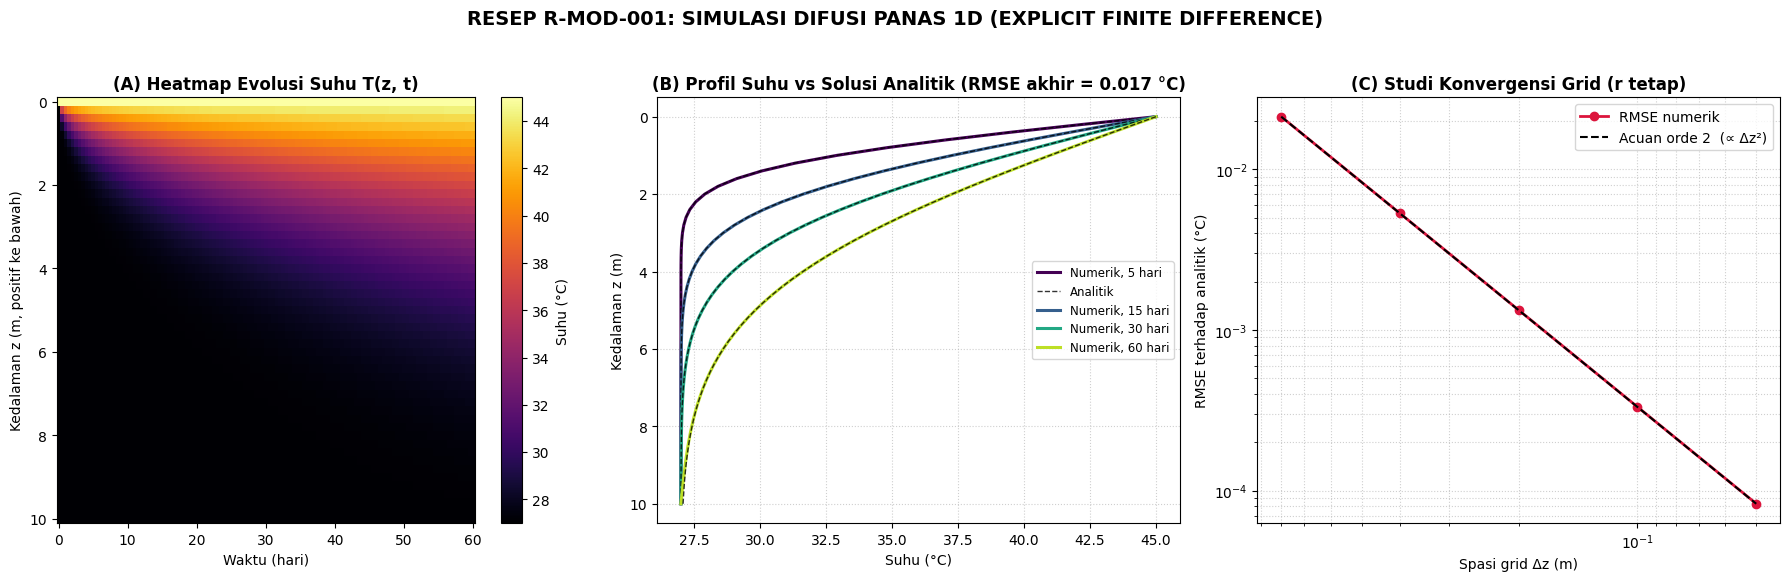

In [3]:
# --- Visualisasi: heatmap, profil vs analitik, dan konvergensi ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))

# (A) Heatmap T(z,t)
t_days = t_saved / HARI
pcm = axes[0].pcolormesh(t_days, z, T_hist.T, shading="auto", cmap="inferno")
axes[0].invert_yaxis()
axes[0].set_xlabel("Waktu (hari)"); axes[0].set_ylabel("Kedalaman z (m, positif ke bawah)")
axes[0].set_title("(A) Heatmap Evolusi Suhu T(z, t)", fontweight="bold")
cb = fig.colorbar(pcm, ax=axes[0]); cb.set_label("Suhu (°C)")

# (B) Profil numerik vs analitik pada beberapa waktu
cols = plt.cm.viridis(np.linspace(0, 0.9, 4))
for c, d in zip(cols, [5, 15, 30, 60]):
    idx = int(np.argmin(np.abs(t_days - d)))
    axes[1].plot(T_hist[idx], z, "-", color=c, lw=2.2, label=f"Numerik, {d} hari")
    axes[1].plot(analytic_semi_infinite(z, t_saved[idx], params["kappa"], params["T_init"], params["T_top"]),
                 z, "k--", lw=1.0, alpha=0.8, label="Analitik" if d == 5 else None)
axes[1].invert_yaxis(); axes[1].grid(True, ls=":", alpha=0.6)
axes[1].set_xlabel("Suhu (°C)"); axes[1].set_ylabel("Kedalaman z (m)")
axes[1].set_title(f"(B) Profil Suhu vs Solusi Analitik (RMSE akhir = {rmse:.3f} °C)", fontweight="bold")
axes[1].legend(fontsize=8.5, loc="center right")

# (C) Konvergensi grid
axes[2].loglog(df_conv["dz_m"], df_conv["RMSE_C"], "o-", color="crimson", lw=2, label="RMSE numerik")
ref = df_conv["RMSE_C"].iloc[0] * (df_conv["dz_m"] / df_conv["dz_m"].iloc[0])**2
axes[2].loglog(df_conv["dz_m"], ref, "k--", label="Acuan orde 2  (∝ Δz²)")
axes[2].invert_xaxis(); axes[2].grid(True, which="both", ls=":", alpha=0.6)
axes[2].set_xlabel("Spasi grid Δz (m)"); axes[2].set_ylabel("RMSE terhadap analitik (°C)")
axes[2].set_title("(C) Studi Konvergensi Grid (r tetap)", fontweight="bold")
axes[2].legend()

plt.suptitle("RESEP R-MOD-001: SIMULASI DIFUSI PANAS 1D (EXPLICIT FINITE DIFFERENCE)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

#### **Analisis Resep 9:**
- Konfigurasi memakai 51 node ($\Delta z = 0{,}2$ m), 720 langkah waktu ($\Delta t = 2$ jam), 121 waktu tersimpan, dan $\kappa = 1{,}2\times10^{-6}\ m^2/s$. Rasio kestabilan $r = 0{,}216$ sehingga memenuhi syarat $r \le 1/2$. Percobaan dengan $\Delta t = 40.000$ s menghasilkan $r = 1{,}196$ dan **ditolak** dengan pesan yang jelas.
- Setelah 60 hari, panjang difusi $L_d = \sqrt{\kappa t} \approx 2{,}49$ m. Pada kedalaman 5 m (sekitar $2L_d$) suhu baru naik dari 27 °C menjadi sekitar 29,8 °C, sedangkan di kedalaman 10 m (sekitar $4L_d$) hampir tidak terpengaruh. Pola ini konsisten dengan sifat difusi: gangguan panas merambat **perlahan** dan **melemah** ke bawah, dengan jarak penetrasi $\propto \sqrt{t}$, bukan $\propto t$.
- RMSE antara profil numerik dan analitik hanya sekitar **0,017 °C** (galat maksimum sekitar 0,069 °C). Galat ini terutama berasal dari batas bawah: solver memakai suhu tetap 27 °C pada $z = 10$ m, sedangkan solusi analitik semi-tak-hingga masih memberi kenaikan sekitar 0,085 °C di kedalaman itu. Karena itu node bawah dikeluarkan dari RMSE sebagaimana dicatat buku.
- Studi konvergensi pada domain 20 m (sehingga batas bawah tidak mengganggu) menunjukkan RMSE turun sekitar 4× setiap $\Delta z$ dibagi dua, yaitu orde konvergensi ≈ 2. Ini sesuai harapan teoretis skema FTCS dengan $r$ tetap (galat $\sim O(\Delta t + \Delta z^2)$ dan $\Delta t \propto \Delta z^2$).
- **Batas klaim:** hasil ini adalah *verification* terhadap solusi analitik dan **bukan validasi** terhadap data borehole nyata. Nilai $\kappa$ adalah asumsi sintetis; kalibrasi dan data lapangan independen diperlukan sebelum dipakai untuk interpretasi.

## **BAGIAN 2: RESEP 10 (R-GEM-012)**
### **Case Study: Layered Geothermal Gradient dan Heat-Flux Diagnostic**

#### **1. Problem**
Gradien temperatur yang berubah terhadap kedalaman sering keliru diberi label "konveksi" atau "perubahan rezim", padahal **perubahan konduktivitas termal batuan juga mengubah gradien konduktif**. Resep ini memisahkan dua hal tersebut dengan menghitung gradien **dan** fluks panas per interval secara eksplisit, lengkap dengan tanda dan satuan.

#### **2. Minimal Theory (kedalaman positif ke bawah)**
Untuk interval dengan panjang $L$: gradien $G = \Delta T / L$ (K/m) dan konduktivitas $k$ (W/(m·K)). Pada konduksi 1D, tunak (*steady*), tanpa sumber panas:
$$q_z = -k_{eff}\,G, \qquad q_{up} = -q_z, \qquad k_{eff} = \frac{L}{\sum_j \ell_j / k_j}$$
dengan $\ell_j$ panjang irisan interval dengan lapisan ke-$j$. Bentuk **resistansi termal seri** ini memungkinkan satu interval melintasi batas lapisan (*interface*).

**Konvensi tanda:** $z$ positif ke bawah, sehingga bila suhu naik terhadap kedalaman ($G > 0$) maka $q_z < 0$ (arah $+z$), artinya panas mengalir **ke atas**, dan $q_{up} > 0$. Jadi "$q_z$ negatif" dan "flux ke atas positif" **tidak saling bertentangan**.

**Batas asumsi:** model ini steady-state, bukan solver transien seperti R-MOD-002, dan tidak boleh dipakai memaksakan kesetimbangan pada log yang belum stabil setelah pengeboran.

**Prompt buku (P-GEM-012), ringkasan:** hitung gradien interval, resistansi konduktif, $q_z$, dan flux ke atas dengan satuan eksplisit; **tolak** konduktivitas tidak valid, depth duplikat, nilai non-finite, dan celah antar-lapisan; uji profil sintetis fluks-konstan sebelum dipakai pada data lapangan; simpan CSV, JSON, dan plot; **jangan** menetapkan konveksi hanya dari gradien yang mendekati nol atau berubah.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, os

# ---------- Data contract: validasi input (menolak data yang tidak valid) ----------
def validate_inputs(depth, temp, layers):
    depth = np.asarray(depth, float); temp = np.asarray(temp, float)
    if depth.shape != temp.shape or depth.ndim != 1 or depth.size < 2:
        raise ValueError("depth dan temp harus 1D, sama panjang, minimal 2 titik")
    if not (np.all(np.isfinite(depth)) and np.all(np.isfinite(temp))):
        raise ValueError("Ada nilai non-finite (NaN/inf) pada depth atau temperatur")
    if np.any(np.diff(depth) == 0):
        raise ValueError("Ada depth duplikat")
    if np.any(np.diff(depth) < 0):
        raise ValueError("Depth harus naik monoton (positif ke bawah)")
    ls = sorted(layers, key=lambda l: l["top"])
    for l in ls:
        if not (np.isfinite(l["k"]) and l["k"] > 0):
            raise ValueError(f"Konduktivitas tidak valid pada layer {l.get('name')}: k={l['k']}")
        if l["bottom"] <= l["top"]:
            raise ValueError(f"Layer {l.get('name')} memiliki top >= bottom")
    for a, b in zip(ls[:-1], ls[1:]):
        if not np.isclose(a["bottom"], b["top"]):
            raise ValueError(f"Gap/overlap layer antara {a['bottom']} m dan {b['top']} m")
    if depth[0] < ls[0]["top"] - 1e-9 or depth[-1] > ls[-1]["bottom"] + 1e-9:
        raise ValueError("Layer tidak menutup seluruh rentang depth data")
    return depth, temp, ls

# ---------- Diagnostik per interval (resistansi termal seri) ----------
def interval_diagnostics(depth, temp, layers):
    depth, temp, ls = validate_inputs(depth, temp, layers)
    rows = []
    for i in range(len(depth) - 1):
        z1, z2 = depth[i], depth[i + 1]; L = z2 - z1
        res, overlaps = 0.0, []
        for l in ls:
            ov = max(0.0, min(z2, l["bottom"]) - max(z1, l["top"]))
            if ov > 0:
                res += ov / l["k"]; overlaps.append(l["name"].split(" (")[0])
        k_eff = L / res                       # W/(m K)
        G = (temp[i + 1] - temp[i]) / L       # K/m
        qz = -k_eff * G                       # W/m2, positif ke bawah
        rows.append(dict(z_top_m=z1, z_bot_m=z2, L_m=L, dT_K=temp[i+1] - temp[i],
                         G_K_per_km=G * 1000.0, k_eff_W_mK=k_eff, R_m2K_W=res,
                         qz_W_m2=qz, q_up_W_m2=-qz, layers="+".join(overlaps)))
    return pd.DataFrame(rows)

# ---------- Profil sintetis fluks-konstan (kebenaran acuan) ----------
def synthetic_constant_flux(depth, layers, q_up, T0):
    ls = sorted(layers, key=lambda l: l["top"])
    return np.array([T0 + q_up * sum(max(0.0, min(zz, l["bottom"]) - l["top"]) / l["k"] for l in ls)
                     for zz in depth])

# ---------- Input sintetis (5 titik, 0-200 m) ----------
LAYERS = [dict(name="Lapisan A (lempung-pasir)", top=0.0,  bottom=80.0,  k=2.5),
          dict(name="Lapisan B (batupasir-tuf)", top=80.0, bottom=200.0, k=3.5)]
depth_m = np.array([0.0, 50.0, 100.0, 150.0, 200.0])
Q_REF, T_SURF = 0.07, 26.0          # W/m2 (70 mW/m2), °C

# Skenario A: fluks konduktif konstan -> harus dipulihkan persis
T_A = synthetic_constant_flux(depth_m, LAYERS, Q_REF, T_SURF)
df_A = interval_diagnostics(depth_m, T_A, LAYERS)

# Skenario B: profil "lapangan" sintetis dengan gangguan suhu pada 150 m dan 200 m
T_B = T_A.copy(); T_B[3] -= 0.30; T_B[4] -= 0.30
df_B = interval_diagnostics(depth_m, T_B, LAYERS)

pd.set_option("display.width", 200)
print("=== SKENARIO A: PROFIL SINTETIS FLUKS KONSTAN (q_up acuan = 0.070 W/m2) ===")
print(pd.DataFrame({"z (m)": T_A}, index=depth_m).T.round(3).to_string())
print(df_A.round(5).to_string(index=False))
err_A = float(np.max(np.abs(df_A["q_up_W_m2"] - Q_REF)))
print(f"\nGalat flux maksimum terhadap acuan sintetis: {err_A:.2e} W/m2")
assert err_A < 1e-12, "Uji fluks konstan gagal"

=== SKENARIO A: PROFIL SINTETIS FLUKS KONSTAN (q_up acuan = 0.070 W/m2) ===
       0.0    50.0   100.0  150.0  200.0
z (m)   26.0   27.4  28.64  29.64  30.64
 z_top_m  z_bot_m  L_m  dT_K  G_K_per_km  k_eff_W_mK  R_m2K_W  qz_W_m2  q_up_W_m2              layers
     0.0     50.0 50.0  1.40        28.0     2.50000 20.00000    -0.07       0.07           Lapisan A
    50.0    100.0 50.0  1.24        24.8     2.82258 17.71429    -0.07       0.07 Lapisan A+Lapisan B
   100.0    150.0 50.0  1.00        20.0     3.50000 14.28571    -0.07       0.07           Lapisan B
   150.0    200.0 50.0  1.00        20.0     3.50000 14.28571    -0.07       0.07           Lapisan B

Galat flux maksimum terhadap acuan sintetis: 9.71e-17 W/m2


#### **3. Check (Uji Penolakan Input dan Uji Counterexample)**
Resep ini menuntut penolakan input yang tidak valid. Empat kasus buruk diuji di bawah; semuanya **harus** memunculkan `ValueError`. Setelah itu skenario B dianalisis dengan penanda *screening* (bukan klasifikasi rezim otomatis).

In [5]:
# --- Uji penolakan input tidak valid ---
kasus_buruk = {
    "depth duplikat":     dict(depth=[0, 50, 50, 100, 150], temp=[26, 27, 28, 29, 30], layers=LAYERS),
    "nilai NaN":          dict(depth=depth_m, temp=[26, np.nan, 28, 29, 30],           layers=LAYERS),
    "konduktivitas <= 0": dict(depth=depth_m, temp=T_A, layers=[{**LAYERS[0], "k": -1.0}, LAYERS[1]]),
    "celah antar-layer":  dict(depth=depth_m, temp=T_A, layers=[LAYERS[0], {**LAYERS[1], "top": 90.0}]),
}
for nama, kw in kasus_buruk.items():
    try:
        interval_diagnostics(**kw); raise AssertionError(f"{nama} seharusnya ditolak")
    except ValueError as e:
        print(f"[DITOLAK] {nama:<20s} -> {e}")

# --- Skenario B: screening deviasi flux (BUKAN klasifikasi rezim) ---
q_ref_B = df_B["q_up_W_m2"].median()
df_B["dev_vs_median_%"] = (df_B["q_up_W_m2"] / q_ref_B - 1.0) * 100.0
df_B["status_screening"] = np.where(df_B["dev_vs_median_%"].abs() > 15.0, "TINJAU ULANG", "konsisten")
print("\n=== SKENARIO B: PROFIL SINTETIS DENGAN GANGGUAN SUHU ===")
print(pd.DataFrame({"z (m)": T_B}, index=depth_m).T.round(3).to_string())
print(df_B[["z_top_m","z_bot_m","G_K_per_km","k_eff_W_mK","q_up_W_m2","dev_vs_median_%","status_screening"]]
      .round(4).to_string(index=False))

# --- Simpan keluaran (CSV, JSON) ---
os.makedirs("hasil_resep10", exist_ok=True)
df_A.assign(skenario="A").pipe(lambda a: pd.concat([a, df_B.assign(skenario="B")], ignore_index=True)) \
    .to_csv("hasil_resep10/geothermal_gradient_analysis.csv", index=False)
with open("hasil_resep10/heat_flow_diagnostic.json", "w", encoding="utf-8") as f:
    json.dump({"recipe": "R-GEM-012", "depth_positive_down": True,
               "q_ref_W_m2": Q_REF, "max_flux_error_A_W_m2": err_A,
               "interpretation": "Rezim aliran panas tidak diinfer otomatis dari gradien saja.",
               "skenario_B_flag": df_B["status_screening"].tolist()}, f, indent=2, ensure_ascii=False)
print("\nTersimpan: hasil_resep10/geothermal_gradient_analysis.csv & heat_flow_diagnostic.json")

[DITOLAK] depth duplikat       -> Ada depth duplikat
[DITOLAK] nilai NaN            -> Ada nilai non-finite (NaN/inf) pada depth atau temperatur
[DITOLAK] konduktivitas <= 0   -> Konduktivitas tidak valid pada layer Lapisan A (lempung-pasir): k=-1.0
[DITOLAK] celah antar-layer    -> Gap/overlap layer antara 80.0 m dan 90.0 m

=== SKENARIO B: PROFIL SINTETIS DENGAN GANGGUAN SUHU ===
       0.0    50.0   100.0  150.0  200.0
z (m)   26.0   27.4  28.64  29.34  30.34
 z_top_m  z_bot_m  G_K_per_km  k_eff_W_mK  q_up_W_m2  dev_vs_median_% status_screening
     0.0     50.0        28.0      2.5000      0.070             -0.0        konsisten
    50.0    100.0        24.8      2.8226      0.070              0.0        konsisten
   100.0    150.0        14.0      3.5000      0.049            -30.0     TINJAU ULANG
   150.0    200.0        20.0      3.5000      0.070              0.0        konsisten

Tersimpan: hasil_resep10/geothermal_gradient_analysis.csv & heat_flow_diagnostic.json


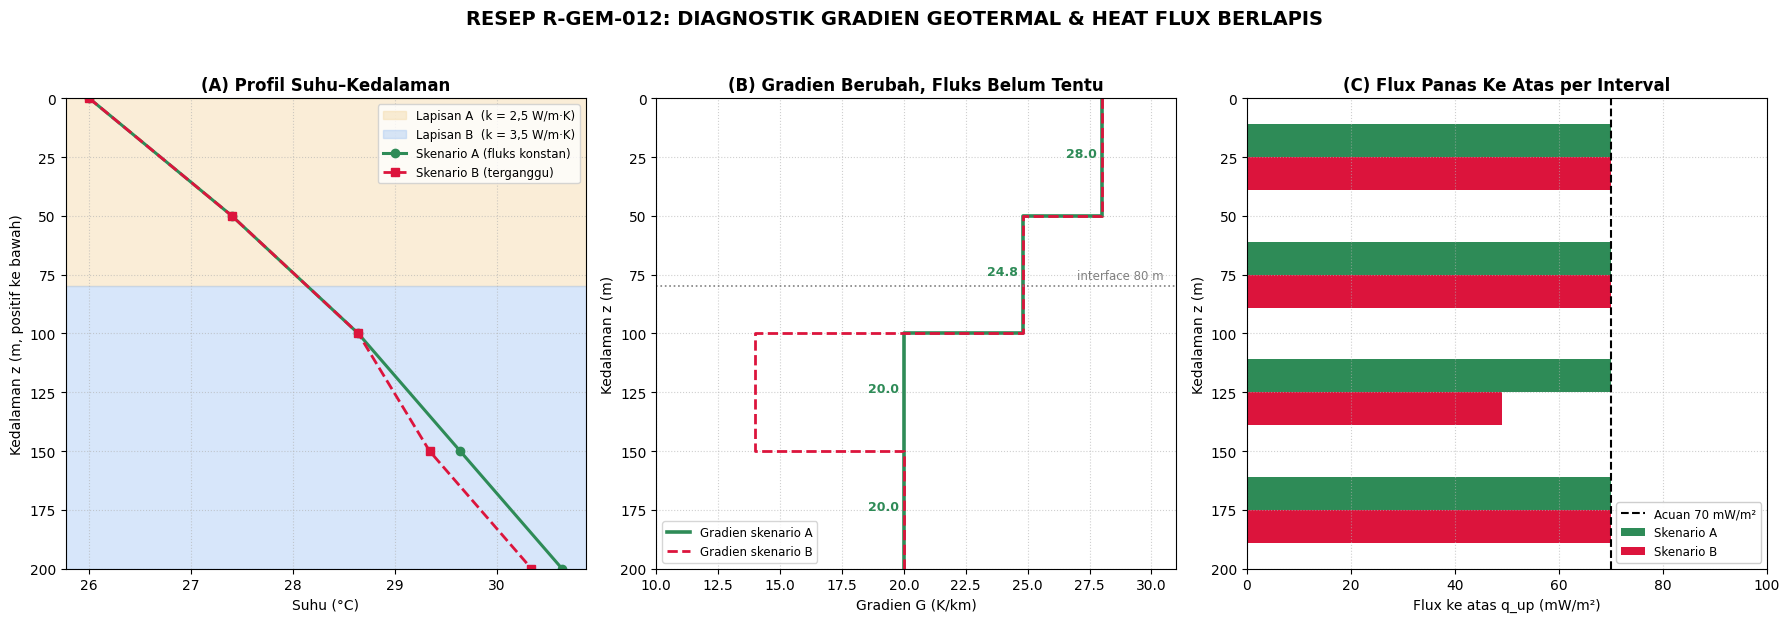

In [6]:
# --- Visualisasi diagnostik ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
mid = 0.5 * (depth_m[:-1] + depth_m[1:])

# (A) Profil suhu-kedalaman + bayangan layer
ax = axes[0]
ax.axhspan(0, 80, color="#f4d9a8", alpha=0.45, label="Lapisan A  (k = 2,5 W/m·K)")
ax.axhspan(80, 200, color="#a8c8f4", alpha=0.45, label="Lapisan B  (k = 3,5 W/m·K)")
ax.plot(T_A, depth_m, "o-", color="seagreen", lw=2.2, label="Skenario A (fluks konstan)")
ax.plot(T_B, depth_m, "s--", color="crimson", lw=2.0, label="Skenario B (terganggu)")
ax.set_ylim(200, 0); ax.grid(True, ls=":", alpha=0.6)
ax.set_xlabel("Suhu (°C)"); ax.set_ylabel("Kedalaman z (m, positif ke bawah)")
ax.set_title("(A) Profil Suhu–Kedalaman", fontweight="bold"); ax.legend(fontsize=8.5, loc="upper right")

# (B) Gradien per interval: berubah walau fluks konstan
ax = axes[1]
yy = np.repeat(depth_m, 2)[1:-1]
ax.plot(np.repeat(df_A["G_K_per_km"].values, 2), yy, color="seagreen", lw=2.6, label="Gradien skenario A")
ax.plot(np.repeat(df_B["G_K_per_km"].values, 2), yy, color="crimson", lw=2.0, ls="--", label="Gradien skenario B")
for zc, gA in zip(mid, df_A["G_K_per_km"]):
    ax.annotate(f"{gA:.1f}", (gA, zc), textcoords="offset points", xytext=(-26, 0), fontsize=9, color="seagreen", fontweight="bold")
ax.axhline(80, color="gray", ls=":", lw=1.2); ax.text(30.5, 78, "interface 80 m", ha="right", va="bottom", fontsize=8.5, color="gray")
ax.set_xlim(10, 31); ax.set_ylim(200, 0); ax.grid(True, ls=":", alpha=0.6)
ax.set_xlabel("Gradien G (K/km)"); ax.set_ylabel("Kedalaman z (m)")
ax.set_title("(B) Gradien Berubah, Fluks Belum Tentu", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower left")

# (C) Flux ke atas per interval
ax = axes[2]
w = 14
ax.barh(mid - w/2, df_A["q_up_W_m2"]*1000, height=w, color="seagreen", label="Skenario A")
ax.barh(mid + w/2, df_B["q_up_W_m2"]*1000, height=w, color="crimson", label="Skenario B")
ax.axvline(Q_REF*1000, color="k", ls="--", label=f"Acuan {Q_REF*1000:.0f} mW/m²")
ax.set_ylim(200, 0); ax.grid(True, ls=":", alpha=0.6)
ax.set_xlim(0, 100); ax.set_xlabel("Flux ke atas q_up (mW/m²)"); ax.set_ylabel("Kedalaman z (m)")
ax.set_title("(C) Flux Panas Ke Atas per Interval", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower right", framealpha=0.95)

plt.suptitle("RESEP R-GEM-012: DIAGNOSTIK GRADIEN GEOTERMAL & HEAT FLUX BERLAPIS", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

#### **Analisis Resep 10:**
- Pada skenario A (profil sintetis fluks konstan 0,070 W/m²) gradien **berubah** dari 28,0 → 24,8 → 20,0 → 20,0 K/km, tetapi $q_{up}$ di keempat interval tetap **0,070 W/m²** dengan galat maksimum $\sim10^{-16}$ W/m² (di bawah ambang $10^{-12}$). Ini *counterexample* inti resep: perubahan gradien **tidak otomatis** berarti perubahan rezim atau konveksi.
- Interval 50–100 m melintasi batas lapisan di 80 m. Dengan resistansi seri, $k_{eff} = 50/(30/2{,}5 + 20/3{,}5) \approx 2{,}82$ W/(m·K), berada di antara 2,5 dan 3,5, dan flux tetap benar. Bila interval ini hanya diberi satu nilai $k$ (misalnya 2,5), hasilnya keliru.
- Konvensi tanda konsisten: karena $T$ naik terhadap kedalaman, $q_z = -0{,}070$ W/m² (arah $+z$, ke bawah negatif) dan $q_{up} = +0{,}070$ W/m². Keduanya menyatakan panas mengalir **ke atas**.
- Pada skenario B, gangguan suhu 0,30 K pada 150 m dan 200 m membuat flux interval 100–150 m turun menjadi sekitar 0,049 W/m² (sekitar −30% dari median) dan ditandai **TINJAU ULANG**. Penanda ini hanya *screening*: penyebabnya bisa berupa konduktivitas yang keliru, log yang belum setimbang setelah pengeboran, aliran fluida (advektif), atau sumber panas. Resep **tidak** menyimpulkan konveksi secara otomatis.
- Empat input buruk (depth duplikat, NaN, $k \le 0$, celah antar-layer) semuanya ditolak dengan pesan yang jelas, sesuai kontrak data buku.
- **Batas klaim:** suhu dan konduktivitas bersifat sintetis. Sebelum dipakai pada log lapangan diperlukan kalibrasi sensor, riwayat ekuilibrasi sumur, referensi kedalaman, dan estimasi ketidakpastian $k$.

## **REKAPITULASI VERIFIKASI & KESIMPULAN**

In [7]:
rekap = pd.DataFrame([
    ["R-MOD-001", "Kestabilan r = κΔt/Δz² ≤ 0,5",                f"r = {info['stability_r']:.3f}; dt berlebih ditolak", "LOLOS"],
    ["R-MOD-001", "Regresi spasi aktual & waktu akhir tepat",   f"dz aktual {s['dz_actual']:.4f} m; t akhir {s['final_time_s']:.0f} s", "LOLOS"],
    ["R-MOD-001", "RMSE vs solusi analitik (domain 10 m)",       f"{rmse:.4f} °C", "LOLOS" if rmse < 0.05 else "PERIKSA"],
    ["R-MOD-001", "Orde konvergensi grid (domain 20 m)",         f"{df_conv['orde_konvergensi'].iloc[-1]:.2f} (harapan ≈ 2)", "LOLOS" if abs(df_conv['orde_konvergensi'].iloc[-1]-2) < 0.1 else "PERIKSA"],
    ["R-GEM-012", "Pemulihan flux konstan (sintetis)",           f"galat maks {err_A:.1e} W/m²", "LOLOS" if err_A < 1e-12 else "PERIKSA"],
    ["R-GEM-012", "Penolakan 4 jenis input tidak valid",         f"{len(kasus_buruk)}/{len(kasus_buruk)} ditolak", "LOLOS"],
    ["R-GEM-012", "Konsistensi tanda q_z dan q_up",              "q_z < 0 dan q_up > 0 (T naik terhadap z)", "LOLOS" if (df_A['qz_W_m2'] < 0).all() and (df_A['q_up_W_m2'] > 0).all() else "PERIKSA"],
], columns=["Resep", "Pemeriksaan", "Hasil", "Status"])
print(rekap.to_string(index=False))
assert (rekap["Status"] == "LOLOS").all(), "Ada pemeriksaan yang belum lolos"
print("\nSemua pemeriksaan verifikasi LOLOS.")

    Resep                              Pemeriksaan                                    Hasil Status
R-MOD-001             Kestabilan r = κΔt/Δz² ≤ 0,5           r = 0.216; dt berlebih ditolak  LOLOS
R-MOD-001 Regresi spasi aktual & waktu akhir tepat      dz aktual 0.3333 m; t akhir 10800 s  LOLOS
R-MOD-001    RMSE vs solusi analitik (domain 10 m)                                0.0174 °C  LOLOS
R-MOD-001      Orde konvergensi grid (domain 20 m)                       2.00 (harapan ≈ 2)  LOLOS
R-GEM-012        Pemulihan flux konstan (sintetis)                  galat maks 9.7e-17 W/m²  LOLOS
R-GEM-012      Penolakan 4 jenis input tidak valid                              4/4 ditolak  LOLOS
R-GEM-012           Konsistensi tanda q_z dan q_up q_z < 0 dan q_up > 0 (T naik terhadap z)  LOLOS

Semua pemeriksaan verifikasi LOLOS.


#### **Kesimpulan**
1. **Resep 9 (R-MOD-001)** menghasilkan *reference solver* difusi panas 1D yang stabil, mencatat spasi/langkah waktu aktual, dan cocok dengan solusi analitik (RMSE ≈ 0,017 °C) dengan konvergensi orde 2. Jarak penetrasi panas mengikuti $\sqrt{\kappa t}$, sehingga setelah 60 hari gangguan di permukaan hanya terasa jelas sampai kedalaman beberapa meter.
2. **Resep 10 (R-GEM-012)** menunjukkan bahwa gradien suhu saja **tidak cukup** untuk menyimpulkan rezim perpindahan panas: gradien dapat berubah 28 → 20 K/km sementara flux konduktif tetap 70 mW/m². Diagnostik berbasis resistansi seri dan penolakan input yang ketat menjaga interpretasi tetap dapat diperiksa.
3. Kedua resep saling melengkapi: Resep 9 adalah model **transien** (perambatan gangguan panas terhadap waktu), sedangkan Resep 10 adalah diagnostik **steady-state** (pembacaan gradien dan flux). Pembedaan asumsi ini penting bila keduanya dipakai bersama pada data geotermal nyata.
4. Seluruh hasil adalah *verification* pada data sintetis, bukan *validation* lapangan; klaim ilmiah baru boleh dibuat setelah dikalibrasi dan dibandingkan dengan data independen.